# A14 weather risk lines: humid spells and late-season dry spells

Two pest and disease lines for the cards, computed from our daily data for every LGA, crop season and year (docs/pest-risk.md, feature 2). They are shown on cards, never scored.

- **Humid spell (maize, sorghum):** 5 or more days in a row, inside the crop's season, with relative humidity at or above the LGA's own 90th percentile for that month (POWER RH2M) and a mean temperature of 20 to 32 C. Leaf blights are favoured by warm, humid weather. A fixed humidity threshold would fire every rainy season, because Kaduna's rainy-season humidity is high everywhere.
- **Late dry spell (groundnut):** 10 or more dry days in a row (under 1 mm, CHIRPS) in the 4 weeks before harvest, when drought raises aflatoxin.

Season windows (plant and harvest dates) come from A9. Thresholds: `config/models.yaml` (`risk_lines`). Formulas: `model/risk_lines.py`.

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import risk_lines as rl
from model.io import write_csv
from model.settings import load_model_config
from model.water_pipeline import canonical_lga

## 1. Season windows and daily weather, one LGA spelling

In [4]:
# Load A9's season windows (plant to harvest, per LGA, year and crop), POWER daily humidity
# and temperature, and CHIRPS daily rain, all with one LGA spelling.
# Scope: all 23 Kaduna LGAs.
cfg = load_model_config()
r = cfg.risk_lines
lgas = sorted(cfg.lga_zone)
windows = pd.read_csv(
    cfg.paths.output_dir / "a9" / "a9_lga_year_crop.csv", parse_dates=["plant_date", "harvest_date"]
)
windows["lga"] = canonical_lga(windows["lga"], lgas)
power = pd.read_parquet(cfg.paths.power_daily, columns=["lga", "date", "RH2M", "T2M"])
power["lga"] = canonical_lga(power["lga"], lgas)
rain = pd.read_csv(cfg.paths.rain_daily, parse_dates=["date"], usecols=["lga", "date", "precip_mm"])
rain["lga"] = canonical_lga(rain["lga"], lgas)
{
    "season windows": len(windows),
    "LGAs": windows["lga"].nunique(),
    "POWER days": len(power),
    "CHIRPS days": len(rain),
}

{'season windows': 9315,
 'LGAs': 23,
 'POWER days': 385250,
 'CHIRPS days': 384307}

## 2. Humid spells in the maize and sorghum seasons

In [5]:
# Flag humid days against each LGA-month's own 90th percentile, keep the days inside each
# maize and sorghum season, and find the longest humid run per season.
power = rl.add_humid_flag(power, r.humid.rh_quantile, *r.humid.t_mean_c)
humid_windows = windows[windows["crop"].isin(r.humid.crops)]
days = rl.season_days(power, humid_windows)
longest = rl.longest_run(days["humid"], [days["lga"], days["crop"], days["year"]])
humid = rl.share_of_seasons(longest, r.humid.min_days, humid_windows).assign(line="humid_spell")
humid.groupby("crop")["share_all_years"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
crop,,,,,,,,
maize,23.0,0.15,0.03,0.09,0.13,0.16,0.18,0.22
sorghum,23.0,0.15,0.03,0.09,0.13,0.16,0.18,0.22


## 3. Late dry spells before the groundnut harvest

In [6]:
# Narrow each groundnut season to its last 4 weeks, flag dry days (under 1 mm), and find the
# longest dry run per season.
rain["dry"] = rain["precip_mm"] < r.late_dry.dry_day_mm
late_windows = rl.add_late_window(
    windows[windows["crop"].isin(r.late_dry.crops)], r.late_dry.weeks_before_harvest
)
days = rl.season_days(rain, late_windows)
longest = rl.longest_run(days["dry"], [days["lga"], days["crop"], days["year"]])
late = rl.share_of_seasons(longest, r.late_dry.min_days, late_windows).assign(line="late_dry_spell")
late.sort_values("share_all_years", ascending=False)[["lga", "share_all_years"]].head(8).round(2)

,lga,share_all_years
4,Ikara,0.53
17,Makarfi,0.49
15,Kudan,0.42
18,Sabon Gari,0.33
22,Zaria,0.27
20,Soba,0.24
2,Giwa,0.22
3,Igabi,0.20


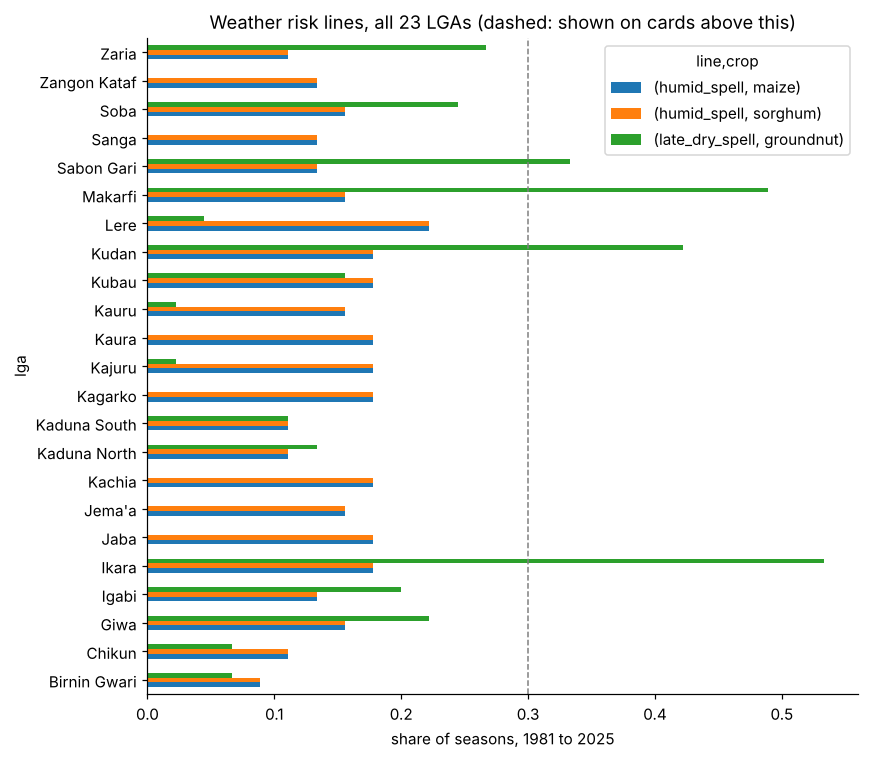

In [7]:
# Both lines for all 23 LGAs, with the share above which a card shows the line.
table = pd.concat([humid, late], ignore_index=True)
pivot = table.pivot_table(index="lga", columns=["line", "crop"], values="share_all_years")
ax = pivot.plot.barh(figsize=(8, 7))
ax.axvline(r.min_share, ls="--", color="grey", lw=1)
ax.set_xlabel("share of seasons, 1981 to 2025")
ax.set_title("Weather risk lines, all 23 LGAs (dashed: shown on cards above this)")
plt.tight_layout()

**Reading.** Humid spells beyond each LGA's normal come in about 1 to 2 of 10 maize seasons everywhere, so the line rarely reaches the card: humidity is not what separates Kaduna's LGAs. Late dry spells before the groundnut harvest are a northern problem: about half of all seasons in Ikara and Makarfi, against almost none in the south. That line will show on northern groundnut cards.

## 4. Save

In [8]:
# Save the table the rotation engine reads.
write_csv(table, cfg.paths.risk_lines)

PosixPath('data/processed/models/a14/a14_lga_crop_risk_lines.csv')